In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report,confusion_matrix
from sklearn.linear_model import LogisticRegression
from imblearn.combine import SMOTETomek

In [2]:
df = pd.read_csv("../Datasets/stroke_prediction_dataset.csv")
df

,Age,Gender,BMI,Hypertension,Diabetes,Heart_disease,Smoking,Alcohol_use,Cholesterol,Blood_glucose,...,Diastolic_BP,Arm_weakness,Leg_weakness,Speech_difficulty,Confusion,Vision_loss,Severe_headache,Family_history,Previous_TIA,Stroke
0,70,Female,35.3,0,1,1,Never,Occasional,222.2,240.7,...,87,1,1,1,0,1,0,0,0,1
1,53,Female,27.3,0,1,0,Current,Regular,228.8,152.4,...,91,1,1,1,1,1,1,1,0,1
2,87,Male,25.7,0,1,1,Former,Never,311.4,145.6,...,106,1,1,0,1,0,0,1,0,1
3,85,Female,33.4,1,0,1,Current,Never,287.3,240.2,...,102,1,1,1,0,0,0,0,1,1
4,51,Female,NaN,0,1,0,NaN,NaN,NaN,NaN,...,110,0,1,1,1,1,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,69,Male,32.9,0,0,0,Never,Never,196.4,85.0,...,88,0,0,0,0,0,0,0,0,0
49996,49,Male,26.9,0,0,0,Current,Regular,222.3,108.4,...,77,0,0,0,0,0,0,0,0,0
49997,27,Male,32.7,0,0,0,Current,Occasional,223.0,105.8,...,81,0,0,0,0,0,0,0,0,0
49998,56,Female,21.1,0,0,0,Former,Regular,217.7,82.7,...,83,0,0,0,0,0,0,0,0,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 22 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Age                50000 non-null  int64  
 1   Gender             50000 non-null  object 
 2   BMI                47500 non-null  float64
 3   Hypertension       50000 non-null  int64  
 4   Diabetes           50000 non-null  int64  
 5   Heart_disease      50000 non-null  int64  
 6   Smoking            48000 non-null  object 
 7   Alcohol_use        48000 non-null  object 
 8   Cholesterol        46500 non-null  float64
 9   Blood_glucose      48500 non-null  float64
 10  Oxygen_saturation  49000 non-null  float64
 11  Systolic_BP        50000 non-null  int64  
 12  Diastolic_BP       50000 non-null  int64  
 13  Arm_weakness       50000 non-null  int64  
 14  Leg_weakness       50000 non-null  int64  
 15  Speech_difficulty  50000 non-null  int64  
 16  Confusion          500

In [4]:
(df.isna().sum() / len(df) ) * 100

Age                  0.0
Gender               0.0
BMI                  5.0
Hypertension         0.0
Diabetes             0.0
Heart_disease        0.0
Smoking              4.0
Alcohol_use          4.0
Cholesterol          7.0
Blood_glucose        3.0
Oxygen_saturation    2.0
Systolic_BP          0.0
Diastolic_BP         0.0
Arm_weakness         0.0
Leg_weakness         0.0
Speech_difficulty    0.0
Confusion            0.0
Vision_loss          0.0
Severe_headache      0.0
Family_history       0.0
Previous_TIA         0.0
Stroke               0.0
dtype: float64

In [5]:
df['BMI'] = df['BMI'].fillna(df['BMI'].median())
df['Smoking'] = df['Smoking'].ffill()
df['Alcohol_use'] = df['Alcohol_use'].ffill()
df['Cholesterol'] = df['Cholesterol'].fillna(df['Cholesterol'].median())
df['Blood_glucose'] = df['Blood_glucose'].fillna(df['Blood_glucose'].median())
df['Oxygen_saturation'] = df['Oxygen_saturation'].fillna(df['Oxygen_saturation'].median())

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
for col in df.columns:
    print(df[col].unique(),col)
    print()

[70 53 87 85 51 93 79 54 59 64 80 60 66 94 57 55 75 67 82 69 50 77 74 52
 84 91 78 68 63 65 61 90 56 83 73 81 86 92 58 62 76 88 72 95 71 89 19 28
 43 22 40 33 49 39 26 34 42 29 44 20 46 37 36 24 21 47 48 27 30 25 31 45
 38 23 32 35 18 41] Age

['Female' 'Male'] Gender

[35.3 27.3 25.7 33.4 28.1 25.6 35.  26.8 27.5 37.8 35.5 30.  27.9 31.3
 30.6 32.9 29.6 33.5 37.1 23.8 24.3 32.3 24.6 26.5 24.5 24.1 28.2 34.3
 36.6 37.5 31.5 32.7 28.4 31.9 33.  29.7 34.2 34.6 36.3 35.4 36.7 27.2
 25.4 30.2 32.8 29.8 30.8 31.  23.6 37.2 37.3 27.4 31.1 26.2 30.5 37.9
 29.9 26.3 33.9 24.  33.2 35.6 30.1 23.2 35.9 35.2 26.1 30.3 23.9 24.9
 25.5 25.1 24.8 29.  26.4 25.3 37.4 25.2 38.  32.4 25.8 36.1 27.7 36.2
 33.6 36.5 37.  31.2 31.4 24.4 36.4 29.2 24.7 28.5 25.9 35.8 28.9 23.1
 28.3 26.6 36.9 35.7 26.7 28.  29.3 27.1 23.4 34.8 34.7 33.3 29.4 26.9
 24.2 23.7 35.1 31.7 25.  32.1 33.7 32.  37.6 33.8 34.  23.3 32.6 37.7
 34.1 28.7 28.6 36.8 30.7 29.1 32.2 34.5 23.  28.8 27.6 30.9 23.5 31.6
 33.1 27.8 36.  32.5

In [8]:
df['Gender'] = df['Gender'].replace({'Male' : 1,'Female' : 0})
df['Smoking'] = df['Smoking'].replace({'Never':0,'Former':1,'Current':2})
df['Alcohol_use'] = df['Alcohol_use'].replace({'Never':0,'Occasional':1,'Regular':2})

C:\Users\kripank\AppData\Local\Temp\ipykernel_27452\3388460460.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Gender'] = df['Gender'].replace({'Male' : 1,'Female' : 0})
C:\Users\kripank\AppData\Local\Temp\ipykernel_27452\3388460460.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Smoking'] = df['Smoking'].replace({'Never':0,'Former':1,'Current':2})
C:\Users\kripank\AppData\Local\Temp\ipykernel_27452\3388460460.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future versi

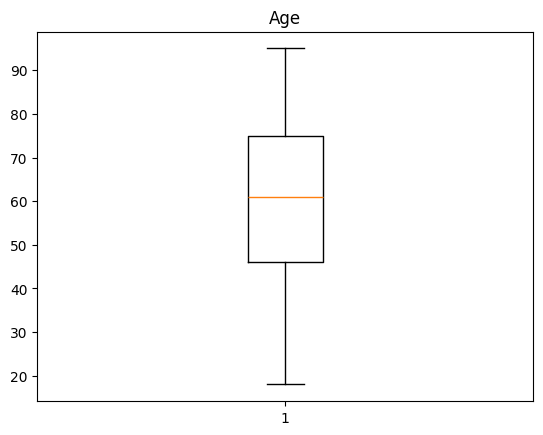

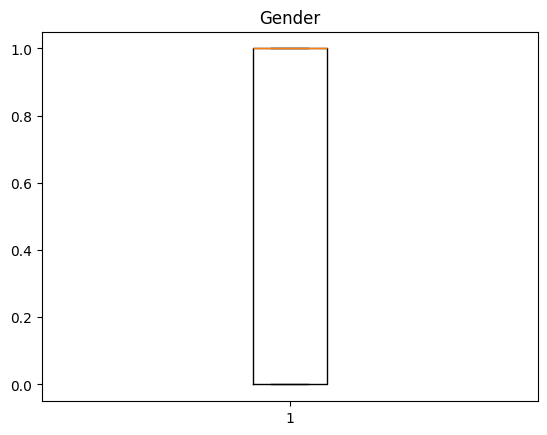

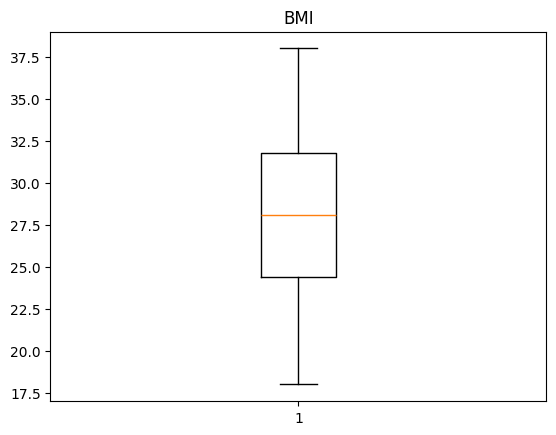

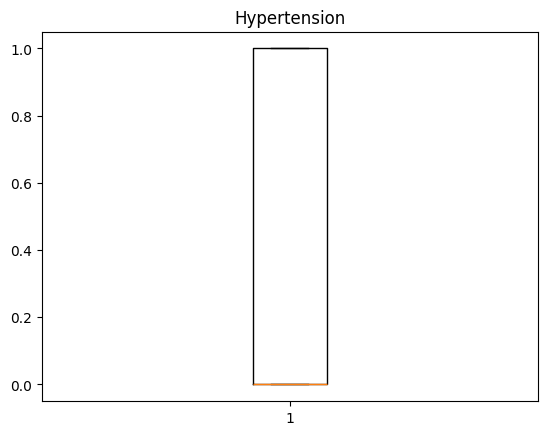

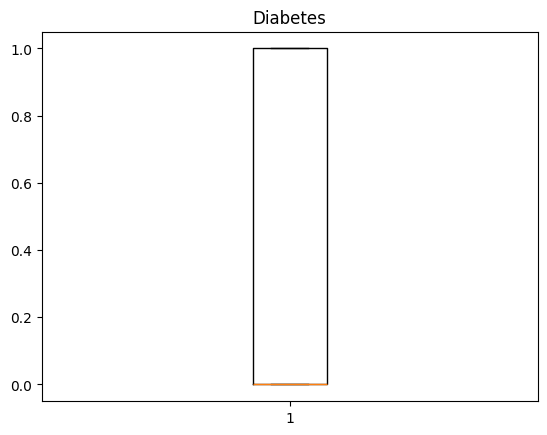

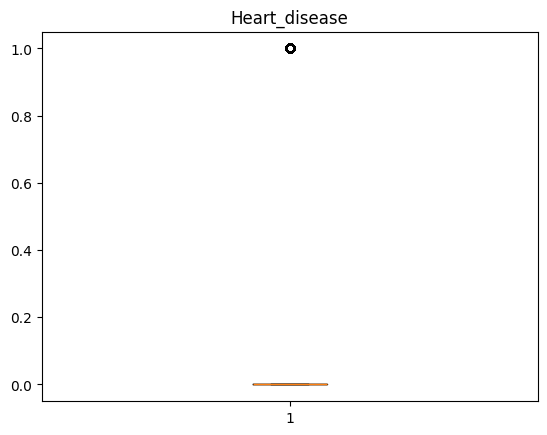

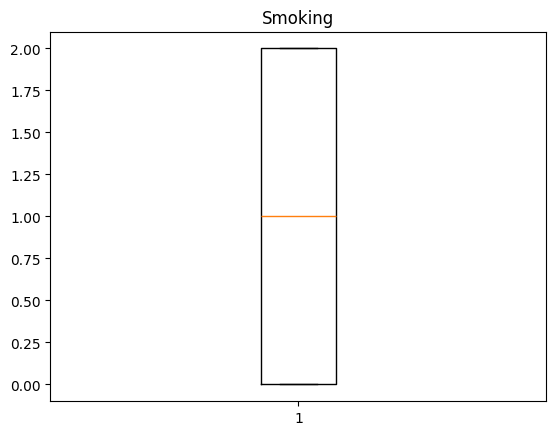

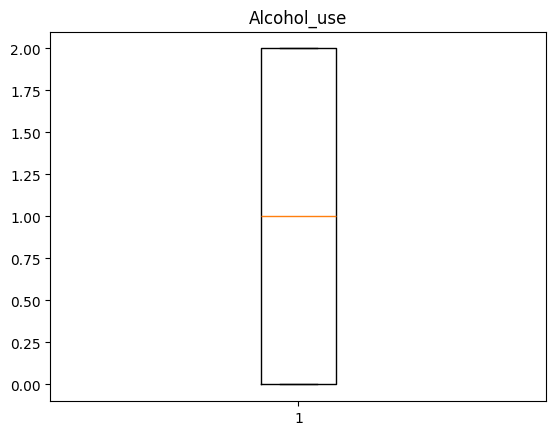

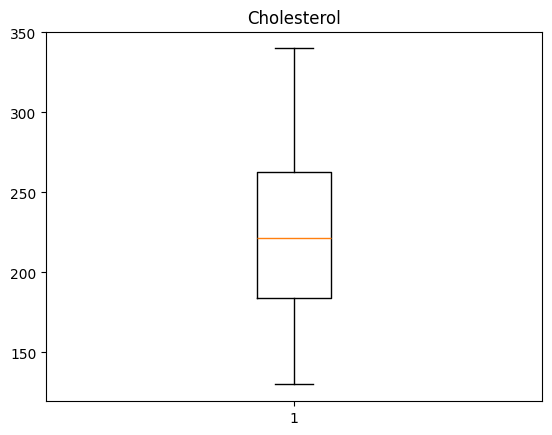

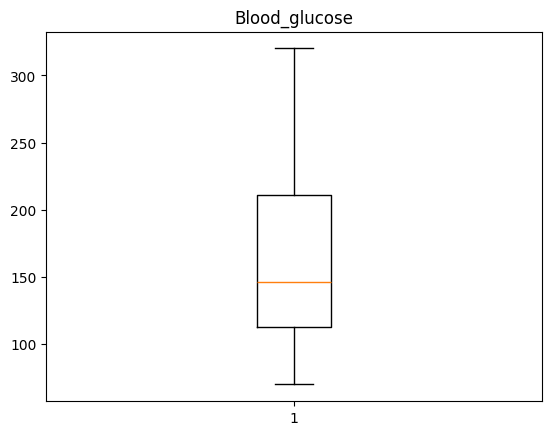

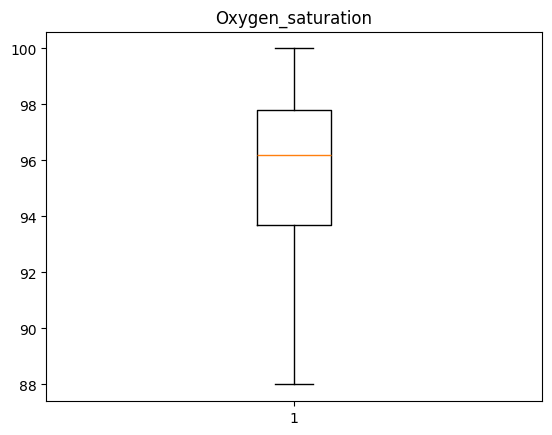

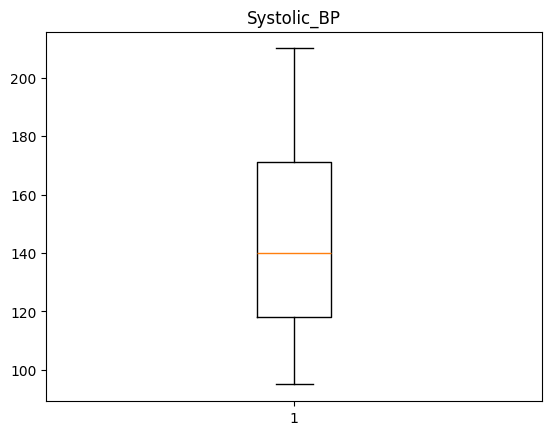

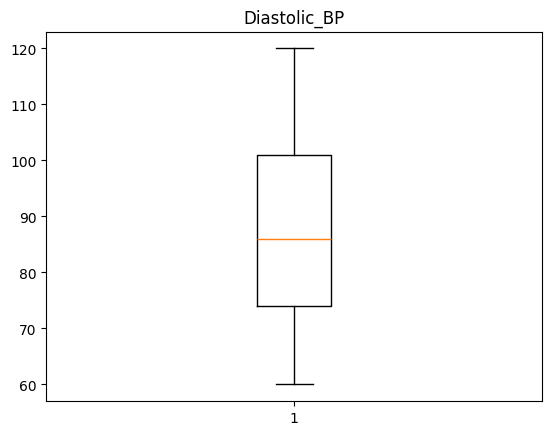

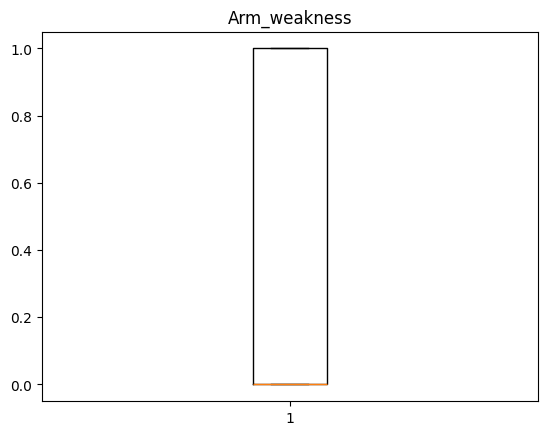

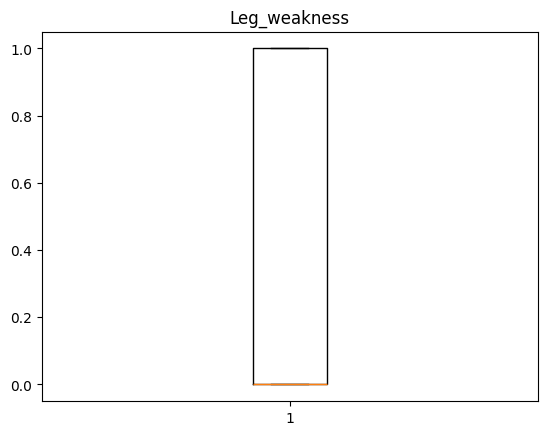

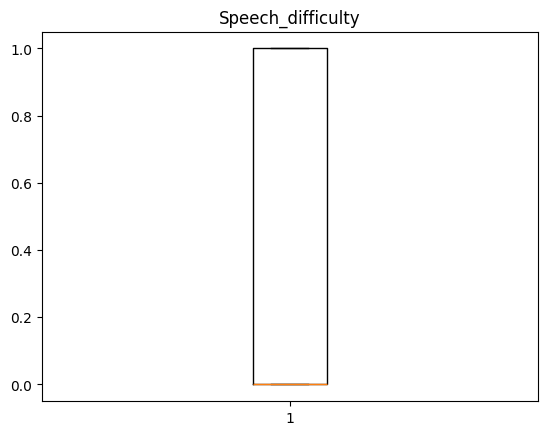

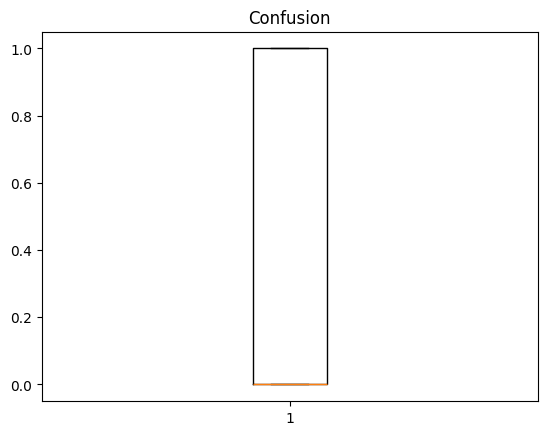

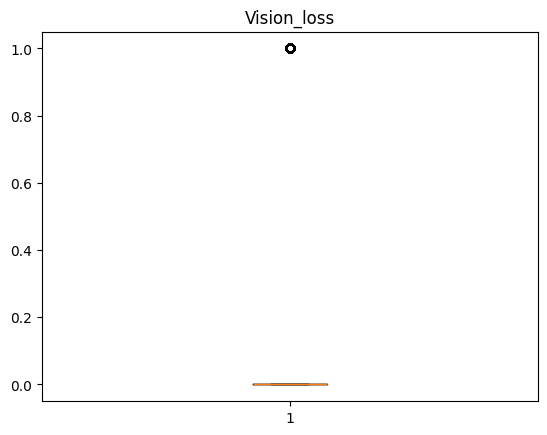

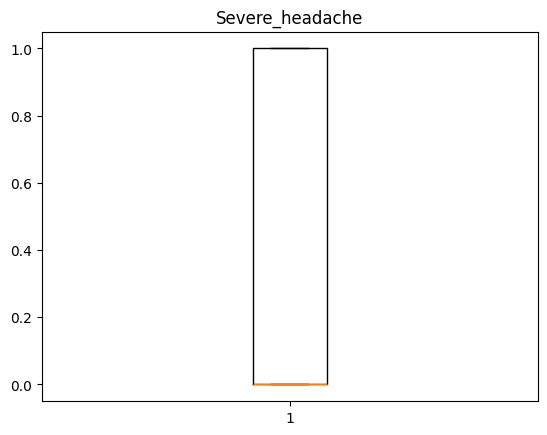

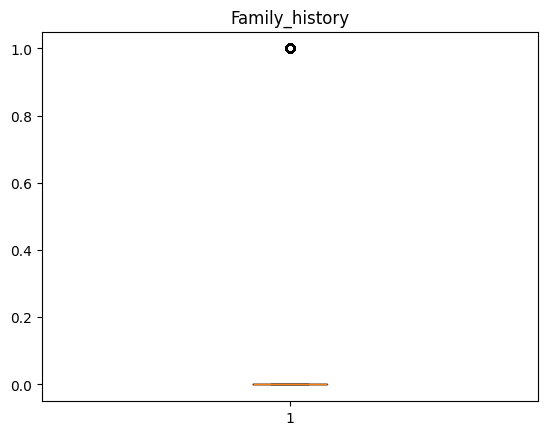

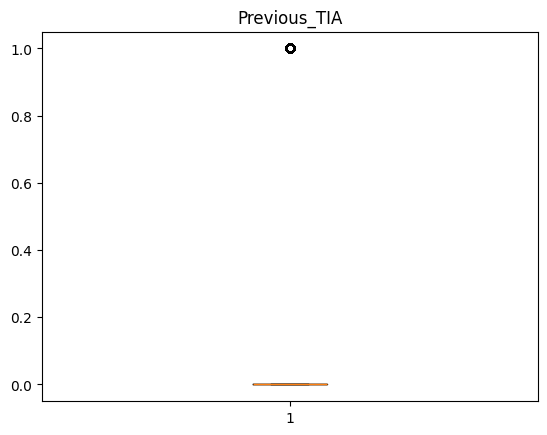

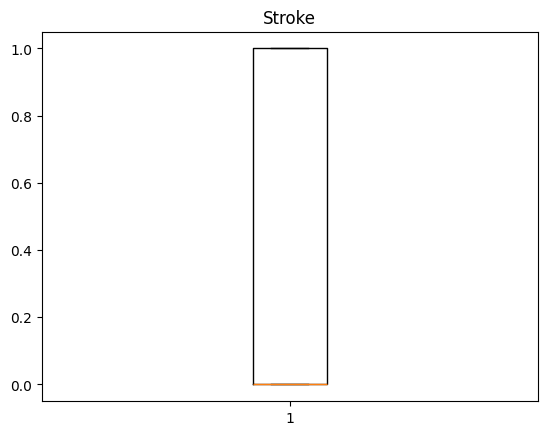

In [9]:
for col in df.columns:
    plt.title(col)
    plt.boxplot(df[col])
    plt.show()

In [10]:
df.corr()["Stroke"]

Age                  0.585400
Gender               0.005451
BMI                  0.439373
Hypertension         0.563810
Diabetes             0.394998
Heart_disease        0.382884
Smoking              0.001469
Alcohol_use          0.008713
Cholesterol          0.762775
Blood_glucose        0.783384
Oxygen_saturation   -0.698228
Systolic_BP          0.841552
Diastolic_BP         0.818520
Arm_weakness         0.793670
Leg_weakness         0.745148
Speech_difficulty    0.765232
Confusion            0.583567
Vision_loss          0.478890
Severe_headache      0.516681
Family_history       0.242775
Previous_TIA         0.419787
Stroke               1.000000
Name: Stroke, dtype: float64

In [11]:
x = df.drop('Stroke',axis=1)
y = df['Stroke']

In [12]:
y.value_counts(normalize=True) 

Stroke
0    0.55
1    0.45
Name: proportion, dtype: float64

In [13]:
x_trian,x_test,y_train,y_test = train_test_split(x,y,random_state=42,test_size=0.2,stratify=y)

In [14]:
smt = SMOTETomek()

In [15]:
scaler = StandardScaler()

In [16]:
train_scaler = scaler.fit_transform(x_trian)
test_scaler = scaler.transform(x_test)

In [17]:
knn = KNeighborsClassifier(n_neighbors=7)
knn.fit(train_scaler,y_train)

,n_neighbors,7
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [18]:
knn_pred = knn.predict(test_scaler)
print(classification_report(y_test,knn_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      5500
           1       1.00      1.00      1.00      4500

    accuracy                           1.00     10000
   macro avg       1.00      1.00      1.00     10000
weighted avg       1.00      1.00      1.00     10000



In [19]:
tree = DecisionTreeClassifier()
tree.fit(x_trian,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [20]:
tree_pred = tree.predict(x_test)
print(classification_report(y_test,tree_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      5500
           1       1.00      1.00      1.00      4500

    accuracy                           1.00     10000
   macro avg       1.00      1.00      1.00     10000
weighted avg       1.00      1.00      1.00     10000

